# 2. Análise exploratória: Ames Housing

**Objetivo:** entender os dados antes de modelar e, principalmente, **decidir como dividir o tempo em "referência" e "atual"** para o teste de drift do Evidently.

Perguntas:
1. Como é a distribuição do preço?
2. O preço e as características das casas mudaram entre 2006 e 2010?
3. O que mais explica o preço?
4. Existe drift natural neste dataset, ou vamos precisar simulá-lo?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

df = pd.read_parquet("../data/processed/ames_clean.parquet")
print(df.shape)
df.dtypes.value_counts()

(2925, 80)


str        44
int64      25
float64    11
Name: count, dtype: int64

## 1. Distribuição do preço

assimetria (skew) original: 1.59
assimetria (skew) com log : -0.04


count      2925.0
mean     180412.0
std       78555.0
min       12789.0
25%      129500.0
50%      160000.0
75%      213500.0
max      625000.0
Name: saleprice, dtype: float64

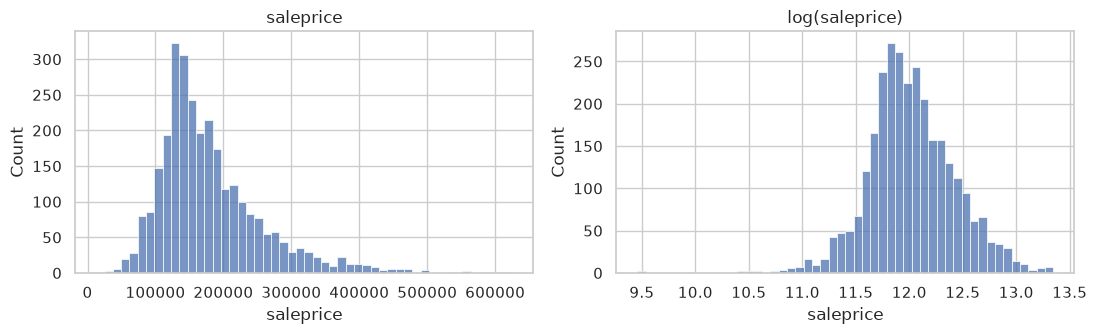

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df["saleprice"], bins=50, ax=ax[0]).set_title("saleprice")
sns.histplot(np.log1p(df["saleprice"]), bins=50, ax=ax[1]).set_title("log(saleprice)")
plt.tight_layout()

print("assimetria (skew) original:", round(df["saleprice"].skew(), 2))
print("assimetria (skew) com log :", round(np.log1p(df["saleprice"]).skew(), 2))
df["saleprice"].describe().round(0)

- **Redução da assimetria:** deixa a distribuição mais simétrica ao comprimir a cauda direita, facilitando análise e visualização.  
- **Menor influência de outliers:** reduz o peso de imóveis muito caros que puxam médias e métricas para cima.  
- **Estabiliza variância (homocedasticidade):** erros tendem a ficar mais uniformes entre observações baratas e caras.  
- **Métricas mais robustas:** melhora comportamento de perdas sensíveis a grandes erros (ex.: MSE), tornando comparações mais estáveis.  
- **Lineariza relações multiplicativas:** relações do tipo “x vezes -> y vezes” ficam mais próximas de uma relação aditiva, beneficiando alguns modelos e interpretações.  
- **Interpretação percentual:** diferenças no espaço logarítmico aproximam variações percentuais, útil para interpretações econômicas.  
- **Previsão e inversão:** ao prever em log, converta de volta com `np.expm1` e considere correção de viés para obter valores na unidade original.

## 2. O preço mudou ao longo dos anos?

,count,mean,median,std
yr_sold,,,,
2006,625,181762.0,159500.0,82620.0
2007,690,183503.0,165000.0,76967.0
2008,621,178872.0,161000.0,75650.0
2009,648,181405.0,160850.0,80857.0
2010,341,172598.0,155000.0,74631.0


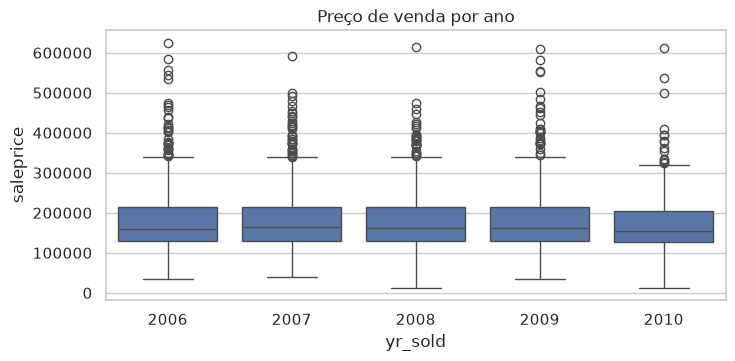

In [4]:
por_ano = df.groupby("yr_sold")["saleprice"].agg(["count", "mean", "median", "std"]).round(0)
display(por_ano)

plt.figure(figsize=(8, 3.5))
sns.boxplot(data=df, x="yr_sold", y="saleprice")
plt.title("Preço de venda por ano")
plt.show()

A mediana fica entre cerca de 155 mil e 165 mil em todos os anos, e a dispersão é parecida. **Não há mudança forte de preço ao longo do tempo.** Isso é relevante: o drift de *target* natural neste dataset é fraco, mesmo com a crise de 2008 no meio do período.

## 3. O que explica o preço?

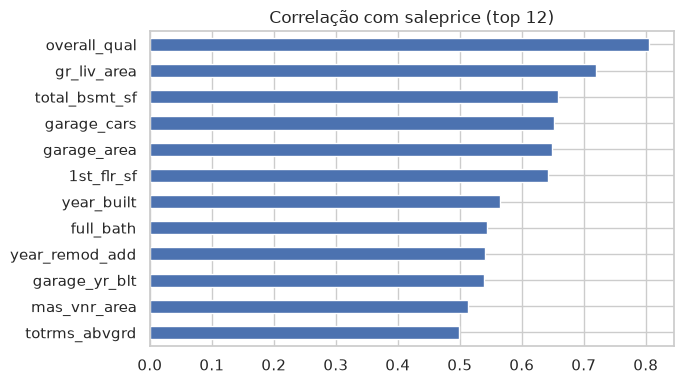

In [5]:
num = df.select_dtypes("number")
corr = num.corr()["saleprice"].drop("saleprice").sort_values(ascending=False)

plt.figure(figsize=(7, 4))
corr.head(12).iloc[::-1].plot.barh()
plt.title("Correlação com saleprice (top 12)")
plt.tight_layout()
plt.show()

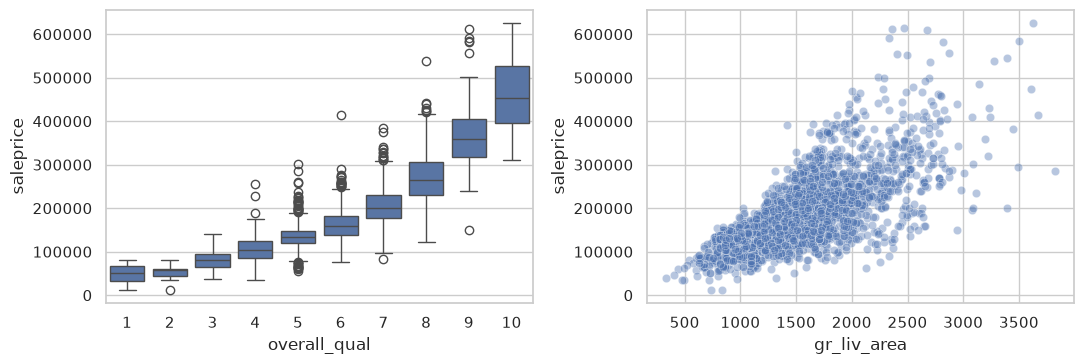

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(data=df, x="overall_qual", y="saleprice", ax=ax[0])
sns.scatterplot(data=df, x="gr_liv_area", y="saleprice", alpha=0.4, ax=ax[1])
plt.tight_layout()

**Relação das duas variáveis mais fortes com o preço**

**Qualidade geral (`overall_qual`):** O preço sobe de forma escalonada: a mediana vai de cerca de 50 mil (nota 1) para cerca de 450 mil (nota 10). A dispersão também cresce com a nota, ou seja, casas de qualidade alta têm preços muito mais variados. Notas vizinhas ainda se sobrepõem, então a qualidade ajuda muito, mas não decide o preço sozinha.

**Área construída (`gr_liv_area`):** A tendência é crescente, com casas maiores custando mais, mas os pontos formam um funil: nas casas pequenas o preço é bem previsível, e nas grandes ele varia muito (uma casa de 2.500 pés² pode custar de 150 mil a 600 mil).

**Consequências para o projeto:**
- Como o modelo será treinado sem log, o funil indica que o erro em dólares tende a ser maior nas casas grandes e caras. Vale conferir isso na análise de erros do Evidently.
- Essas duas variáveis são boas candidatas para o drift sintético: mudar qualquer uma delas no conjunto "atual" deve afetar bastante o erro do modelo.

In [7]:
bairro = df.groupby("neighborhood")["saleprice"].agg(["count", "median"]).sort_values("median")
pd.concat([bairro.head(5), bairro.tail(5)])

,count,median
neighborhood,,
MeadowV,37,88250.0
BrDale,30,106000.0
IDOTRR,93,106500.0
OldTown,239,119900.0
Edwards,191,125000.0
Veenker,24,250250.0
GrnHill,2,280000.0
NoRidge,69,301500.0
NridgHt,166,317750.0
